# PromptPiper — Visualizations

Organized by research question (see §Objectives in the paper):

1. **RQ1** — Trade-off between prompt compression and task performance
2. **RQ2** — How PromptPiper compares to existing baselines
3. **RQ3** — Cost and convergence characteristics
4. **RQ4** — Patterns in compression strategies and transferability

Missing results are skipped gracefully — re-run when new experiments complete.

In [45]:
import json
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

RESULTS_DIR = Path('../results/icse_26')

# ── Figure size constants (IEEE two-column format, inches) ────────────────────
COL1  = 6.3    # single-column width
COL2  = 13   # full text-width (double column)
ROW_H = 2.5    # height per subplot row

FIG_DIR = Path('../paper/prompt_piper_paper/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
# ─────────────────────────────────────────────────────────────────────────────

# Models — display name, directory name, access type
MODELS = [
    ('GPT-5.4-nano',         'gpt-5.4-nano-2026-03-17',     'remote'),
    ('Gemini-3-Flash',       'gemini-3-flash-preview',      'remote'),
    ('Gemma-4-26B',          'gemma-4-26b-a4b-it',          'local'),
    ('Qwen3.5-9B',           'qwen3.5-9b',                  'local'),
]

# All tasks — (run_name_stem, display_label, local_only)
TASKS = [
    ('mbpp_instruct_nsga2',         'MBPP',        False),
    ('mmlu_pro_cs_nsga2',           'MMLU-Pro CS', False),
    ('gsm8k_cot_nsga2',             'GSM8K',       False),
    ('bbh_logical_deduction_nsga2', 'BBH-Logic',   False),
    ('musr_murder_mysteries_nsga2', 'MuSR',        True),
]
COMMON_TASKS  = [(s, l, lo) for s, l, lo in TASKS if not lo]
LOCAL_TASKS   = [(s, l, lo) for s, l, lo in TASKS if lo]

TRANSFER_PAIRS = [
    ('gsm8k_cot_nsga2',             'bbh_logical_deduction_nsga2'),
    ('bbh_logical_deduction_nsga2', 'gsm8k_cot_nsga2'),
]

BASELINE_STYLE = {
    'no_compression':      {'color': '#555555', 'marker': 'D', 'label': 'No compression'},
    'all_transformations': {'color': '#e06c75', 'marker': 's', 'label': 'All transforms'},
    'random_search':       {'color': '#d19a66', 'marker': '^', 'label': 'Random search'},
    'multi_armed_bandit':  {'color': '#e5c07b', 'marker': '*', 'label': 'MAB'},
    'summarization':       {'color': '#c678dd', 'marker': 'P', 'label': 'Summarization'},
    'truncated_prompt':    {'color': '#61afef', 'marker': 'v', 'label': 'Truncated'},
    'random_deletion':     {'color': '#56b6c2', 'marker': 'X', 'label': 'Rand. deletion'},
    'llmlingua2':          {'color': '#98c379', 'marker': 'h', 'label': 'LLMLingua-2'},
}

NSGA2_COLOR   = '#2196F3'
SEARCH_COLOR  = '#90CAF9'

MODEL_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3']

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# ── Loaders ───────────────────────────────────────────────────────────────────

def load_json(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None

def load_jsonl(path):
    try:
        with open(path) as f:
            return [json.loads(l) for l in f]
    except Exception:
        return None

def all_results():
    """Return nested dict: results[model_dir][run_stem] = data."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        mpath = RESULTS_DIR / mdir
        if not mpath.exists():
            continue
        for stem, _, _ in TASKS:
            d = load_json(mpath / f'{stem}.json')
            if d:
                out[mdir][stem] = d
        for src, tgt in TRANSFER_PAIRS:
            d = load_json(mpath / f'transfer_{src}_to_{tgt}.json')
            if d:
                out[mdir][f'transfer_{src}_to_{tgt}'] = d
    return out

def all_detailed():
    """Return nested dict: detailed[model_dir][run_stem] = list of row dicts."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        det_path = RESULTS_DIR / mdir / 'detailed'
        if not det_path.exists():
            continue
        for stem, _, _ in TASKS:
            rows = load_jsonl(det_path / f'{stem}_detailed.jsonl')
            if rows:
                out[mdir][stem] = rows
        for src, tgt in TRANSFER_PAIRS:
            key = f'transfer_{src}_to_{tgt}'
            rows = load_jsonl(det_path / f'{key}_detailed.jsonl')
            if rows:
                out[mdir][key] = rows
    return out

RESULTS  = all_results()
DETAILED = all_detailed()

print('Results loaded:')
for mlabel, mdir, _ in MODELS:
    runs = list(RESULTS[mdir].keys())
    det  = list(DETAILED[mdir].keys())
    print(f'  {mlabel}: {len(runs)} runs, {len(det)} detailed')

Results loaded:
  GPT-5.4-nano: 6 runs, 6 detailed
  Gemini-3-Flash: 6 runs, 6 detailed
  Gemma-4-26B: 7 runs, 6 detailed
  Qwen3.5-9B: 6 runs, 0 detailed


---
## RQ1 — Trade-off between Prompt Compression and Task Performance

> *What is the trade-off between prompt compression and task performance?*

Each subplot shows the NSGA-II Pareto front (search set in light blue, test set in dark blue) and all baselines evaluated on the test set.

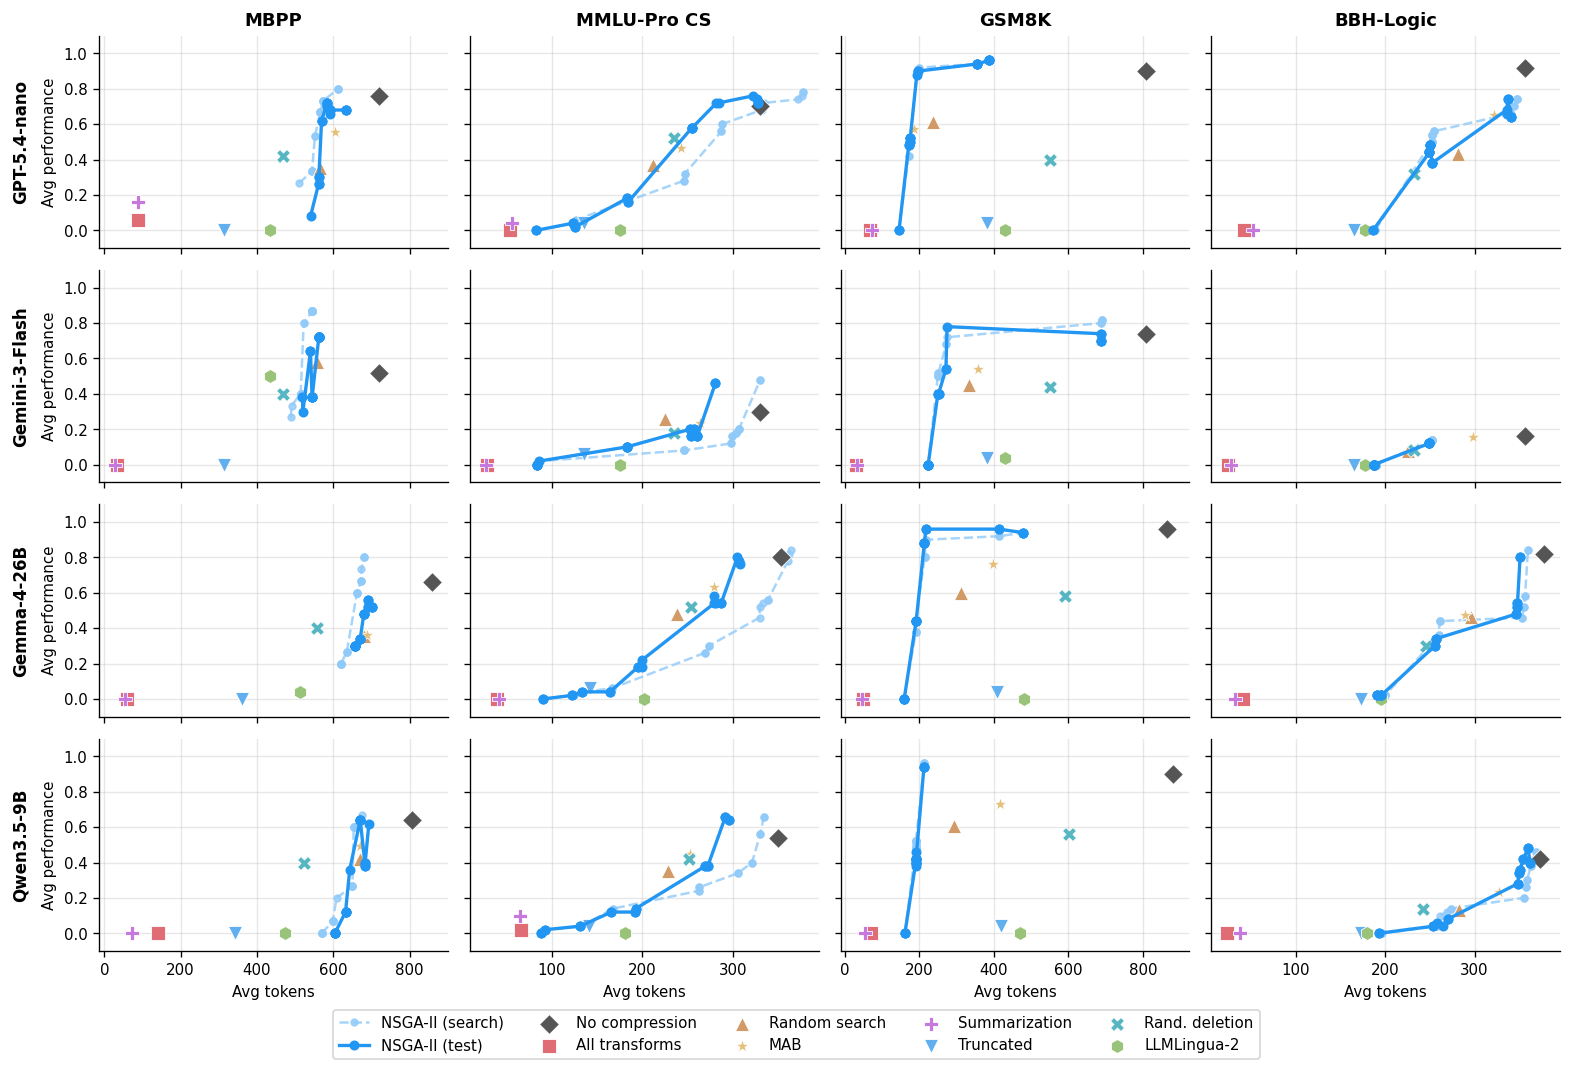

In [46]:
# Helper: extract (tokens, perf) for a list of solutions from JSON
def pareto_xy_json(solutions, split='test'):
    tok  = [s.get(f'{split}_avg_tokens')      or s['search_avg_tokens']      for s in solutions]
    perf = [s.get(f'{split}_avg_performance') or s['search_avg_performance'] for s in solutions]
    return np.array(tok), np.array(perf)

def draw_pareto_front(ax, tokens, perfs, color, label, lw=2, ms=5, ls='-'):
    order = np.argsort(tokens)
    ax.plot(tokens[order], perfs[order], f'o{ls}', color=color, lw=lw,
            markersize=ms, label=label, zorder=6)

def draw_baselines(ax, baselines, split='test'):
    for bl in baselines:
        bname = bl['name']
        if bname not in BASELINE_STYLE:
            continue
        st = BASELINE_STYLE[bname]
        bt = bl.get(f'{split}_avg_tokens')      or bl['search_avg_tokens']
        bp = bl.get(f'{split}_avg_performance') or bl['search_avg_performance']
        ax.scatter(bt, bp, s=80, label=st['label'],
                   color=st['color'], marker=st['marker'],
                   zorder=5, edgecolors='white', linewidths=0.5)


def rq1_grid(task_list, title_suffix='', filename=None):
    available_models = [(lbl, mdir) for lbl, mdir, _ in MODELS
                        if any(stem in RESULTS[mdir] for stem, _, _ in task_list)]
    available_tasks  = [(stem, lbl) for stem, lbl, _ in task_list
                        if any(stem in RESULTS[mdir] for _, mdir, _ in MODELS)]
    if not available_models or not available_tasks:
        print('No data available.')
        return

    nrows, ncols = len(available_models), len(available_tasks)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows * 0.85),
                             squeeze=False,
                             sharey='all', sharex='col')

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(available_models):
        for ci, (stem, tlabel) in enumerate(available_tasks):
            ax = axes[ri][ci]
            ax.set_ylim(-0.1, 1.1)
            ax.set_xlabel('Avg tokens' if ri == nrows - 1 else '')
            ax.set_ylabel('Avg performance' if ci == 0 else '')
            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

            d = RESULTS[mdir].get(stem)
            if d is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                ax.set_visible(True)
                continue

            # Search pareto front
            stok, sperf = pareto_xy_json(d['pareto_solutions'], split='search')
            h, = ax.plot(*[x[np.argsort(stok)] for x in (stok, sperf)],
                         'o--', color=SEARCH_COLOR, lw=1.5, markersize=4,
                         label='NSGA-II (search)', zorder=5, alpha=0.8)
            legend_handles.setdefault('NSGA-II (search)', h)

            # Test pareto front
            ttok, tperf = pareto_xy_json(d['pareto_solutions'], split='test')
            h, = ax.plot(*[x[np.argsort(ttok)] for x in (ttok, tperf)],
                         'o-', color=NSGA2_COLOR, lw=2, markersize=5,
                         label='NSGA-II (test)', zorder=6)
            legend_handles.setdefault('NSGA-II (test)', h)

            # Baselines on test
            for bl in d['baselines']:
                bname = bl['name']
                if bname not in BASELINE_STYLE:
                    continue
                st = BASELINE_STYLE[bname]
                bt = bl.get('test_avg_tokens')       or bl['search_avg_tokens']
                bp = bl.get('test_avg_performance')  or bl['search_avg_performance']
                h = ax.scatter(bt, bp, s=70, color=st['color'], marker=st['marker'],
                               zorder=5, edgecolors='white', linewidths=0.5,
                               label=st['label'])
                legend_handles.setdefault(st['label'], h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(5, len(labels)),
               bbox_to_anchor=(0.5, -0.05), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()


rq1_grid(COMMON_TASKS, filename='rq1_common.pdf')

---
## RQ2 — How PromptPiper Compares to Existing Baselines

> *How does PromptPiper compare to existing baselines for prompt optimization?*

Distributions of per-example **performance** (left column) and **compressed tokens** (right column)
from the detailed results. Rows correspond to benchmarks. Each method's distribution is shown as a violin.

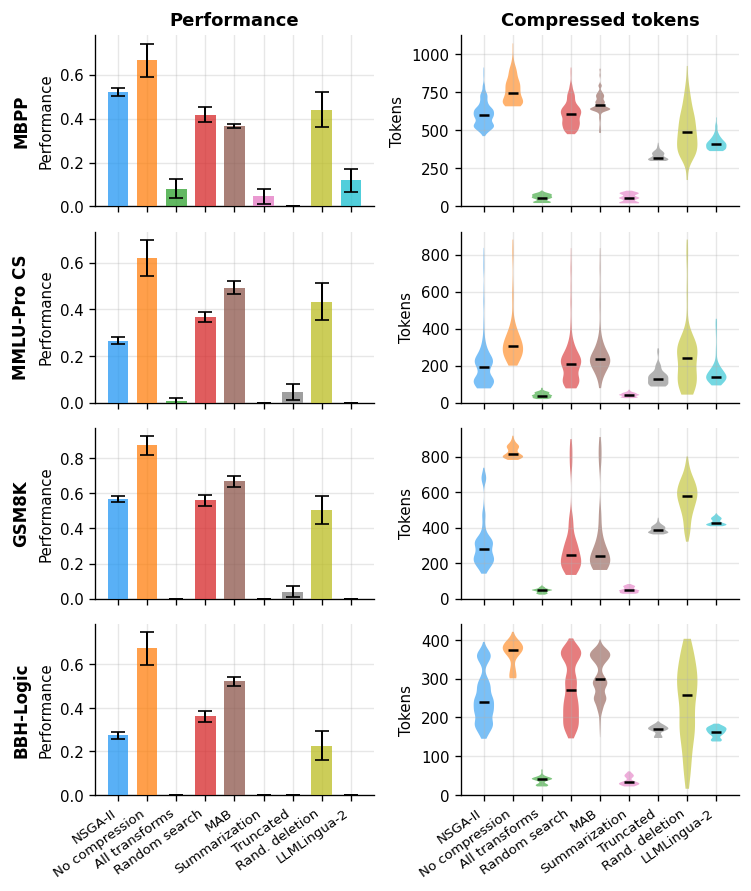

In [47]:
def collect_rq2_data():
    """Collect per-example perf & tokens from detailed results for all models × tasks."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            det = DETAILED[mdir].get(stem)
            if det is None:
                continue
            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    method = 'NSGA-II'
                elif sol_type.startswith('baseline_'):
                    bname = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model': mlabel,
                    'task':  tlabel,
                    'method': method,
                    'performance': row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2 = collect_rq2_data()

if df_rq2.empty:
    print('No detailed results available for RQ2 plots.')
else:
    tasks_with_data  = [l for _, l, _ in TASKS if l in df_rq2['task'].unique()]
    methods_ordered  = (['NSGA-II']
                        + [st['label'] for st in BASELINE_STYLE.values()
                           if st['label'] in df_rq2['method'].unique()])
    methods_ordered  = list(dict.fromkeys(methods_ordered))

    method_colors = {m: c for m, c in zip(
        methods_ordered,
        plt.cm.tab10(np.linspace(0, 1, len(methods_ordered))))}
    method_colors['NSGA-II'] = NSGA2_COLOR

    nrows = len(tasks_with_data)
    ncols = 2  # performance bar | tokens violin

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows * 0.75), sharex='col', squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data):
        sub = df_rq2[df_rq2['task'] == tlabel]

        for ci, (metric, xlabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Compressed tokens')]):
            ax = axes[ri][ci]
            positions = list(range(len(methods_ordered)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_ordered]

            if ci == 0:
                # Bar chart with 95% CI for performance
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    color = method_colors[m]
                    if len(data) == 0:
                        continue
                    mean_val = np.mean(data)
                    ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                    ax.bar(pos, mean_val, width=0.7, color=color, alpha=0.75, zorder=3)
                    ax.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                color='black', capsize=4, linewidth=1.2, zorder=4)
                ax.set_ylim(bottom=0)
            else:
                # Violin for token distribution
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    if len(data) == 0:
                        continue
                    color = method_colors[m]
                    parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                          showmedians=True, showextrema=False)
                    for pc in parts['bodies']:
                        pc.set_facecolor(color)
                        pc.set_alpha(0.6)
                    parts['cmedians'].set_color('black')
                    parts['cmedians'].set_linewidth(1.5)

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_ordered, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(xlabel if ci == 0 else 'Tokens')
            if ci == 1:
                ax.set_ylim([0, None])
            if ri == 0:
                ax.set_title(xlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.3, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq2_distributions.pdf', bbox_inches='tight')
    plt.show()

### RQ2 (variant) — Best Pareto solution only

Same layout as above, but NSGA-II is represented by **a single solution per (model, task)**: the Pareto-front point closest to the ideal point (task performance = 1, normalised token count = 0), using Euclidean distance in that 2-D space. All baselines are unchanged.

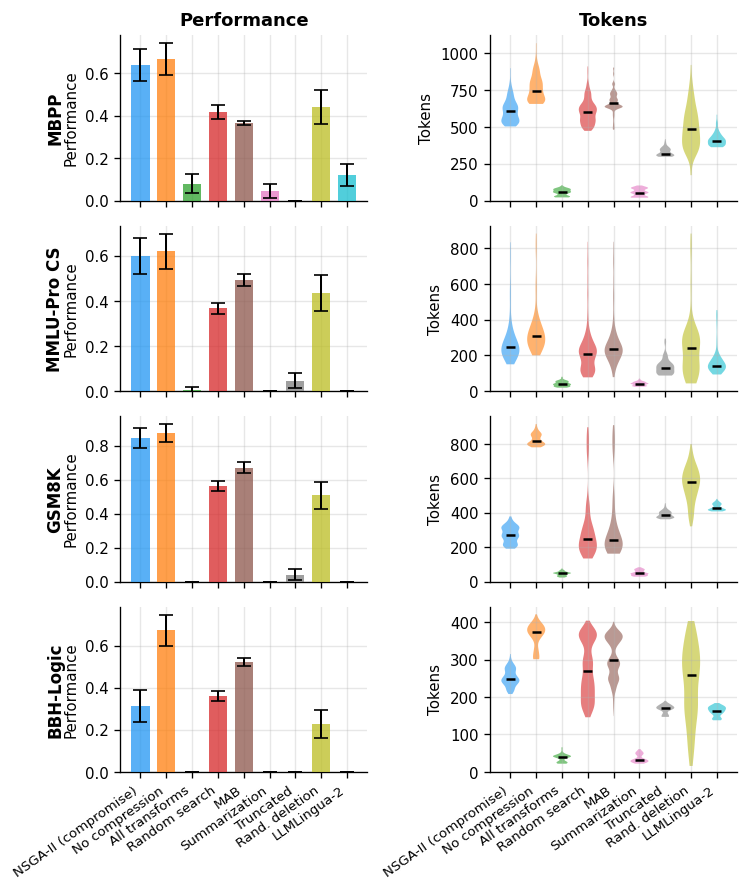

In [48]:
def find_best_pareto_id(pareto_solutions, ref_tokens):
    """Return the index (= solution_id) of the Pareto solution closest to (perf=1, norm_tok=0)."""
    best_id, best_dist = None, float('inf')
    ref_tokens = max(ref_tokens, 1)
    for i, sol in enumerate(pareto_solutions):
        perf = sol.get('test_avg_performance') or sol['search_avg_performance']
        tok  = sol.get('test_avg_tokens')      or sol['search_avg_tokens']
        dist = np.sqrt((1 - perf) ** 2 + (tok / ref_tokens) ** 2)
        if dist < best_dist:
            best_dist, best_id = dist, i
    return best_id


def collect_rq2_best_data():
    """Per-example perf & tokens: NSGA-II = best Pareto solution only; baselines unchanged."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            d   = RESULTS[mdir].get(stem)
            det = DETAILED[mdir].get(stem)
            if d is None or det is None:
                continue

            nc        = next((b for b in d['baselines'] if b['name'] == 'no_compression'), None)
            ref_toks  = (nc.get('test_avg_tokens') or nc['search_avg_tokens']) if nc else 1.0
            best_id   = find_best_pareto_id(d['pareto_solutions'], ref_toks)

            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    if row.get('solution_id') != best_id:
                        continue
                    method = 'NSGA-II (compromise)'
                elif sol_type.startswith('baseline_'):
                    bname  = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model':             mlabel,
                    'task':              tlabel,
                    'method':            method,
                    'performance':       row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2_best = collect_rq2_best_data()

if df_rq2_best.empty:
    print('No detailed results available.')
else:
    tasks_with_data_best = [l for _, l, _ in TASKS if l in df_rq2_best['task'].unique()]
    methods_best = (['NSGA-II (compromise)']
                    + [st['label'] for st in BASELINE_STYLE.values()
                       if st['label'] in df_rq2_best['method'].unique()])
    methods_best = list(dict.fromkeys(methods_best))

    method_colors_best = {m: c for m, c in zip(
        methods_best, plt.cm.tab10(np.linspace(0, 1, len(methods_best))))}
    method_colors_best['NSGA-II (compromise)'] = NSGA2_COLOR

    nrows = len(tasks_with_data_best)
    fig, axes = plt.subplots(nrows, 2,
                             figsize=(COL1, ROW_H * nrows * 0.75),
                             sharex='col', squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data_best):
        sub = df_rq2_best[df_rq2_best['task'] == tlabel]

        for ci, (metric, ylabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Tokens')]):
            ax = axes[ri][ci]
            positions = list(range(len(methods_best)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_best]

            if ci == 0:
                for pos, (m, data) in enumerate(zip(methods_best, data_per_method)):
                    if len(data) == 0:
                        continue
                    mean_val = np.mean(data)
                    ci_val   = (1.96 * np.std(data, ddof=1) / np.sqrt(len(data))
                                if len(data) > 1 else 0)
                    ax.bar(pos, mean_val, width=0.7,
                           color=method_colors_best[m], alpha=0.75, zorder=3)
                    ax.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                color='black', capsize=4, linewidth=1.2, zorder=4)
                ax.set_ylim(bottom=0)
            else:
                for pos, (m, data) in enumerate(zip(methods_best, data_per_method)):
                    if len(data) == 0:
                        continue
                    parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                          showmedians=True, showextrema=False)
                    for pc in parts['bodies']:
                        pc.set_facecolor(method_colors_best[m])
                        pc.set_alpha(0.6)
                    parts['cmedians'].set_color('black')
                    parts['cmedians'].set_linewidth(1.5)
                ax.set_ylim([0, None])

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_best, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(ylabel)
            if ri == 0:
                ax.set_title(ylabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.3, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq2_best_solution_distributions.pdf', bbox_inches='tight')
    plt.show()

---
## RQ3 — Cost and Convergence Characteristics

> *What are the cost and convergence characteristics of different optimization strategies?*

### RQ3.1 — Cumulative search + test time per approach

Box plots showing the distribution of total elapsed time (search + evaluation) across
available runs, broken down by model and benchmark.

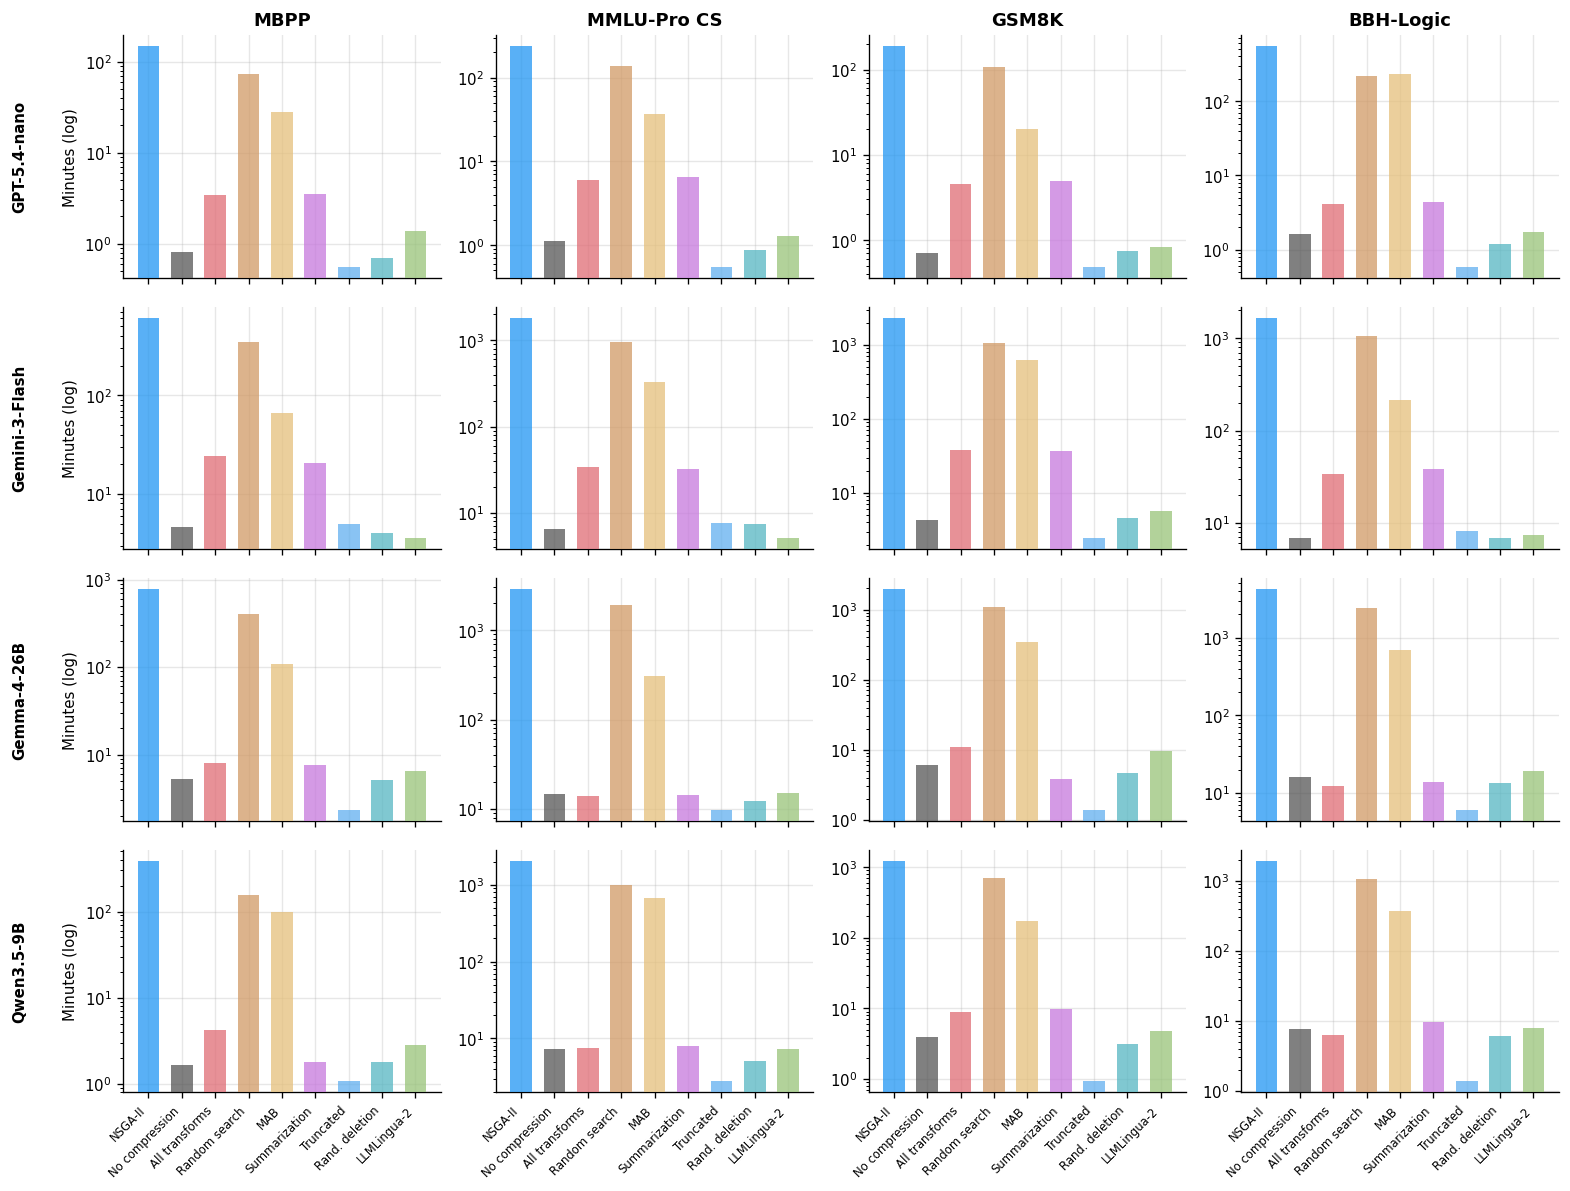

In [49]:
def collect_timing():
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            rows.append({
                'model': mlabel, 'task': tlabel,
                'approach': 'NSGA-II',
                'total_seconds': d['search_elapsed_seconds'] + d['eval_elapsed_seconds'],
            })
            for bl in d['baselines']:
                bname = bl['name']
                label = BASELINE_STYLE.get(bname, {}).get('label', bname)
                rows.append({
                    'model': mlabel, 'task': tlabel,
                    'approach': label,
                    'total_seconds': bl.get('elapsed_seconds', np.nan),
                })
    return pd.DataFrame(rows)


df_time = collect_timing()

if df_time.empty:
    print('No timing data available.')
else:
    df_time['total_minutes'] = df_time['total_seconds'] / 60

    approaches = (['NSGA-II']
                  + [st['label'] for st in BASELINE_STYLE.values()
                     if st['label'] in df_time['approach'].unique()])
    approaches = list(dict.fromkeys(approaches))

    app_colors = ([NSGA2_COLOR]
                  + [BASELINE_STYLE[k]['color']
                     for k in BASELINE_STYLE
                     if BASELINE_STYLE[k]['label'] in approaches[1:]])

    models_present = [lbl for lbl, _, _ in MODELS if lbl in df_time['model'].unique()]
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]

    nrows = len(models_present)
    ncols = len(tasks_present)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows),
                             squeeze=False, sharex='col')

    x = np.arange(len(approaches))
    width = 0.65

    for ri, mlabel in enumerate(models_present):
        for ci, tlabel in enumerate(tasks_present):
            ax = axes[ri][ci]
            sub = df_time[(df_time['model'] == mlabel) & (df_time['task'] == tlabel)]

            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=9, fontweight='bold', rotation=90, va='center')
                ax.set_ylabel('Minutes (log)')

            if sub.empty:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            for pos, (appr, color) in enumerate(zip(approaches, app_colors)):
                val = sub[sub['approach'] == appr]['total_minutes'].dropna().values
                if len(val) == 0 or np.isnan(val[0]):
                    continue
                ax.bar(pos, val[0], width, color=color, alpha=0.75, zorder=3)

            ax.set_xticks(x)
            if ri == nrows - 1:
                ax.set_xticklabels(approaches, rotation=45, ha='right', fontsize=7)
            ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_1_timing.pdf', bbox_inches='tight')
    plt.show()

### RQ3.2 — Time distribution across models (per task)

Box plots showing how each approach's total time varies across models, aggregated per task.

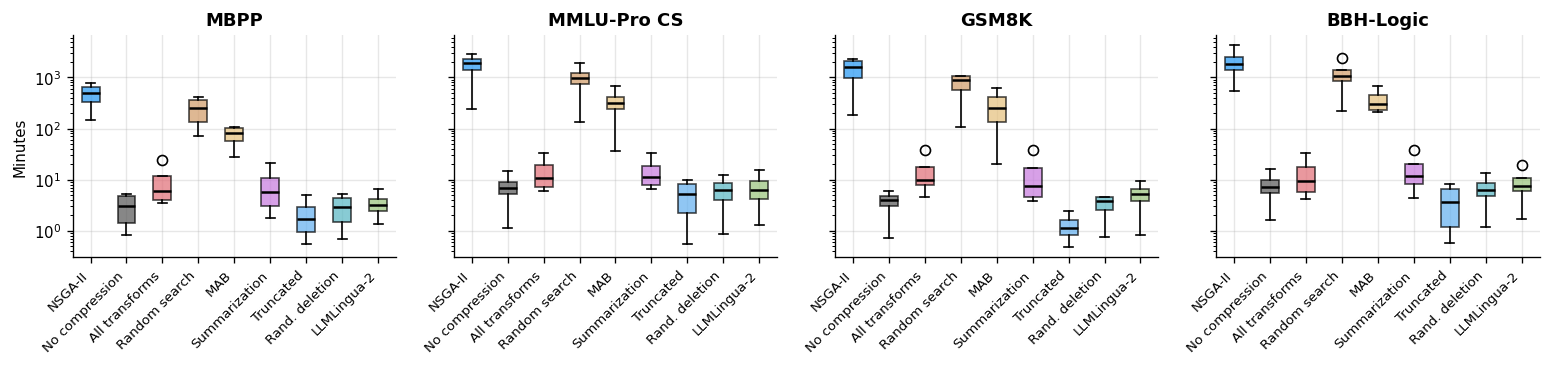

In [50]:
if df_time.empty:
    print('No timing data available.')
else:
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]
    approaches_avail = list(dict.fromkeys(
        ['NSGA-II'] + [st['label'] for st in BASELINE_STYLE.values()
                        if st['label'] in df_time['approach'].unique()]))

    ncols = len(tasks_present)
    fig, axes = plt.subplots(1, ncols, figsize=(COL2, ROW_H * 1.25), squeeze=False, sharey=True)

    for ci, tlabel in enumerate(tasks_present):
        ax = axes[0][ci]
        sub = df_time[df_time['task'] == tlabel]
        data = [sub[sub['approach'] == a]['total_minutes'].dropna().values
                for a in approaches_avail]
        bp = ax.boxplot([d if len(d) else [np.nan] for d in data],
                        labels=approaches_avail, patch_artist=True,
                        medianprops=dict(color='black', lw=1.5))
        colors_bl = ([NSGA2_COLOR]
                     + [BASELINE_STYLE[k]['color']
                        for k in BASELINE_STYLE
                        if BASELINE_STYLE[k]['label'] in approaches_avail[1:]])
        for patch, color in zip(bp['boxes'], colors_bl[:len(bp['boxes'])]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(tlabel, fontweight='bold')
        ax.set_xticklabels(approaches_avail, rotation=45, ha='right', fontsize=8)
        ax.set_ylabel('Minutes' if ci == 0 else '')
        ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_2_timing_boxplots.pdf', bbox_inches='tight')
    plt.show()

### RQ3.3 — Convergence: aggregated per task, averaged across models

Lines show the mean best performance and mean minimum tokens across models. Shaded regions show ±1 standard deviation.

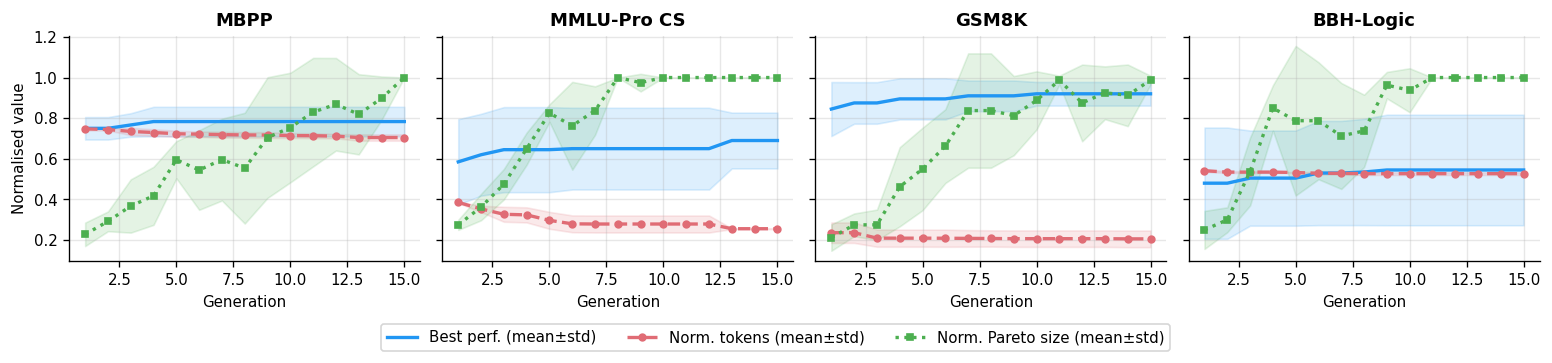

In [51]:
def collect_convergence():
    """Return dict task_label -> list of {model, history, no_compression_tokens}."""
    out = defaultdict(list)
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            history = d.get('generation_history', [])
            if not history:
                continue
            # No-compression token count for normalization
            ref = next((b for b in d['baselines'] if b['name'] == 'no_compression'), None)
            ref_tokens = (ref.get('test_avg_tokens') or ref.get('search_avg_tokens', 1)
                          if ref else 1)
            out[tlabel].append({'model': mlabel, 'history': history,
                                'ref_tokens': ref_tokens})
    return out


conv_data = collect_convergence()

if not conv_data:
    print('No generation history data available.')
else:
    tasks_conv = list(conv_data.keys())
    ncols = min(4, len(tasks_conv))
    nrows = (len(tasks_conv) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, sharey=True,
                             figsize=(COL2, ROW_H * nrows * 1.1), squeeze=False)

    for idx, tlabel in enumerate(tasks_conv):
        ax = axes[idx // ncols][idx % ncols]
        entries = conv_data[tlabel]

        n_gens = max(h['history'][-1]['generation'] for h in entries)
        gens = list(range(1, n_gens + 1))

        all_best_perf   = []
        all_norm_tok    = []
        all_norm_pareto = []

        for entry in entries:
            gen_map = {h['generation']: h for h in entry['history']}
            ref_tok = max(entry['ref_tokens'], 1)
            max_n = max((gen_map[g]['n_solutions'] for g in gens if g in gen_map), default=1)
            max_n = max(max_n, 1)

            bp_series, nt_series, np_series = [], [], []
            for g in gens:
                h = gen_map.get(g)
                if h and h['pareto_front']:
                    bp_series.append(max(s['avg_performance'] for s in h['pareto_front']))
                    nt_series.append(min(s['avg_tokens'] for s in h['pareto_front']) / ref_tok)
                    np_series.append(h['n_solutions'] / max_n)
                else:
                    bp_series.append(np.nan)
                    nt_series.append(np.nan)
                    np_series.append(np.nan)
            all_best_perf.append(bp_series)
            all_norm_tok.append(nt_series)
            all_norm_pareto.append(np_series)

        def plot_mean_std(ax, gens, data, color, label, ls='-', marker=None):
            arr = np.array(data, dtype=float)
            mean = np.nanmean(arr, axis=0)
            std  = np.nanstd(arr, axis=0)
            ax.plot(gens, mean, color=color, lw=2, ls=ls, label=label,
                    marker=marker, markersize=4, markevery=max(1, len(gens)//10))
            ax.fill_between(gens, mean - std, mean + std, color=color, alpha=0.15)

        plot_mean_std(ax, gens, all_best_perf,  '#2196F3', 'Best perf. (mean±std)')
        plot_mean_std(ax, gens, all_norm_tok,   '#e06c75', 'Norm. tokens (mean±std)',  ls='--', marker='o')
        plot_mean_std(ax, gens, all_norm_pareto,'#4caf50', 'Norm. Pareto size (mean±std)', ls=':', marker='s')

        ax.set_xlabel('Generation')
        if idx == 0:
            ax.set_ylabel('Normalised value')
        ax.set_title(tlabel, fontweight='bold')

    for idx in range(len(tasks_conv), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(labels),
               bbox_to_anchor=(0.5, -0.1), frameon=True, fontsize=9)
    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_3_convergence.pdf', bbox_inches='tight')
    plt.show()

---
## RQ4 — Patterns in Compression Strategies and Transferability

> *What patterns emerge in prompt compression strategies and how transferable are they across datasets?*

### RQ4.1 — Transferred Pareto fronts

Each subplot shows the native Pareto front (blue) alongside the transferred solutions from another task (orange). The grey diamond is the no-compression reference.

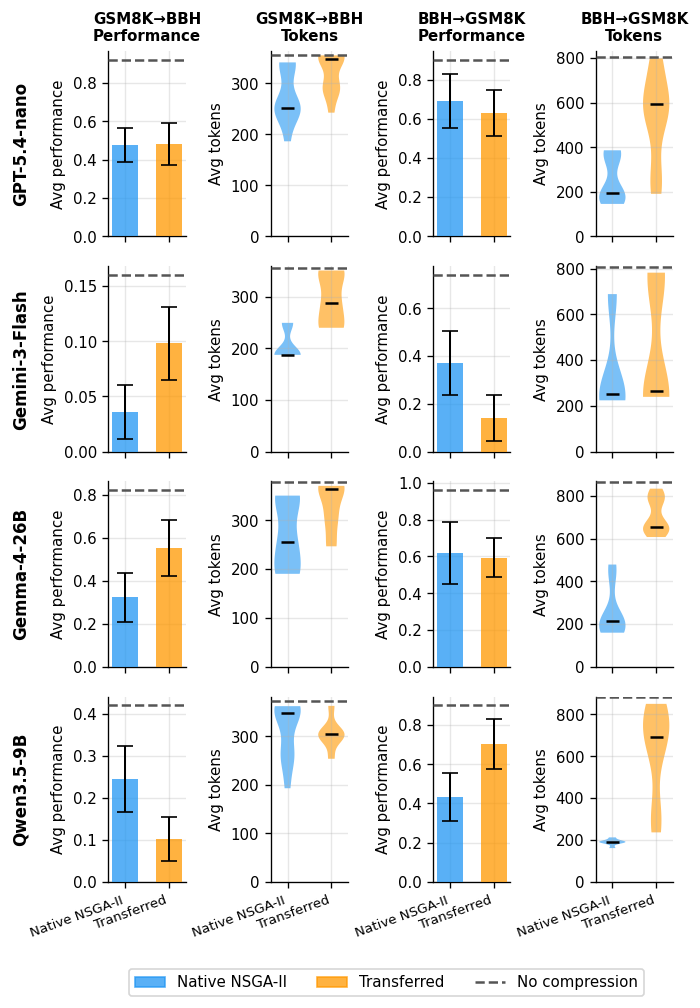

In [52]:
TASK_LABEL_MAP = {stem: lbl for stem, lbl, _ in TASKS}

def rq4_transfer_grid(filename=None):
    models_with_transfer = [
        (lbl, mdir) for lbl, mdir, _ in MODELS
        if any(f"transfer_{s}_to_{t}" in RESULTS[mdir] for s, t in TRANSFER_PAIRS)
    ]
    if not models_with_transfer:
        print("No transfer results available.")
        return

    pairs_avail = list(dict.fromkeys(
        (s, t) for s, t in TRANSFER_PAIRS
        for _, mdir in models_with_transfer
        if f"transfer_{s}_to_{t}" in RESULTS[mdir]
    ))

    nrows = len(models_with_transfer)
    # Each pair has 2 sub-columns: [perf bar, token dist]
    ncols = 2 * len(pairs_avail)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows * 0.8),
                             squeeze=False, sharex="all")

    bar_labels  = ["Native NSGA-II", "Transferred"]
    bar_colors  = [NSGA2_COLOR, "#FF9800"]
    x_positions = [0, 1]

    for ri, (mlabel, mdir) in enumerate(models_with_transfer):
        is_bottom_row = (ri == nrows - 1)
        for pi, (src, tgt) in enumerate(pairs_avail):
            src_lbl = TASK_LABEL_MAP.get(src, src)
            tgt_lbl = TASK_LABEL_MAP.get(tgt, tgt)
            col_perf = pi * 2
            col_tok  = pi * 2 + 1
            ax_perf  = axes[ri][col_perf]
            ax_tok   = axes[ri][col_tok]

            if ri == 0:
                ax_perf.set_title(f"{src_lbl}→{tgt_lbl}\nPerformance".replace("-Logic", ""), fontweight="bold", fontsize=9)
                ax_tok.set_title(f"{src_lbl}→{tgt_lbl}\nTokens".replace("-Logic", ""), fontweight="bold", fontsize=9)
            if pi == 0:
                ax_perf.annotate(mlabel, xy=(-1.25, 0.5), xycoords="axes fraction",
                                 fontsize=10, fontweight="bold", rotation=90, va="center")

            key = f"transfer_{src}_to_{tgt}"
            tr  = RESULTS[mdir].get(key)
            nat = RESULTS[mdir].get(tgt)

            if tr is None:
                for ax in (ax_perf, ax_tok):
                    ax.set_facecolor("#f5f5f5")
                    ax.text(0.5, 0.5, "N/A", transform=ax.transAxes,
                            ha="center", va="center", color="gray",
                            fontsize=11, fontstyle="italic")
                    ax.set_xticks(x_positions)
                    if is_bottom_row:
                        ax.set_xticklabels(bar_labels, rotation=20, ha="right", fontsize=8)
                ax_perf.set_ylabel("Avg performance")
                ax_perf.set_ylim(bottom=0)
                ax_tok.set_ylabel("Avg tokens")
                ax_tok.set_ylim(bottom=0)
                continue

            # Gather per-solution performance and token data
            nat_perfs = np.array([s.get("test_avg_performance") or s["search_avg_performance"]
                                  for s in nat["pareto_solutions"]]) if nat else np.array([])
            nat_toks  = np.array([s.get("test_avg_tokens") or s["search_avg_tokens"]
                                  for s in nat["pareto_solutions"]]) if nat else np.array([])
            tr_perfs  = np.array([s.get("test_avg_performance") or s["search_avg_performance"]
                                  for s in tr["solutions"]])
            tr_toks   = np.array([s.get("test_avg_tokens") or s["search_avg_tokens"]
                                  for s in tr["solutions"]])

            # No-compression reference
            nc_perf   = None
            nc_tokens = None
            if nat:
                ref = next((b for b in nat["baselines"] if b["name"] == "no_compression"), None)
                if ref:
                    nc_perf   = ref.get("test_avg_performance") or ref["search_avg_performance"]
                    nc_tokens = ref.get("test_avg_tokens")       or ref["search_avg_tokens"]

            # ── Left: performance bar chart with 95% CI ─────────────────────────────────
            for pos, (label, data) in zip(x_positions, zip(bar_labels, [nat_perfs, tr_perfs])):
                if len(data) == 0:
                    continue
                mean_val = np.mean(data)
                ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                ax_perf.bar(pos, mean_val, width=0.6, color=bar_colors[pos], alpha=0.75,
                            zorder=3)
                ax_perf.errorbar(pos, mean_val, yerr=ci_val, fmt="none",
                                 color="black", capsize=5, linewidth=1.2, zorder=4)

            if nc_perf is not None:
                ax_perf.axhline(nc_perf, color="#555555", lw=1.5, ls="--", zorder=5)

            ax_perf.set_xticks(x_positions)
            ax_perf.set_ylabel("Avg performance")
            ax_perf.set_ylim(bottom=0)
            if is_bottom_row:
                ax_perf.set_xticklabels(bar_labels, rotation=20, ha="right", fontsize=8)

            # ── Right: token distribution violin plot (positions match bar chart) ──
            tok_data      = [(d, c) for d, c in zip([nat_toks, tr_toks], bar_colors) if len(d) > 0]
            tok_positions = [p for p, d in zip(x_positions, [nat_toks, tr_toks]) if len(d) > 0]
            tok_x_labels  = [l for l, d in zip(bar_labels, [nat_toks, tr_toks]) if len(d) > 0]

            for pos, (data, color) in zip(tok_positions, tok_data):
                if len(data) < 2:
                    ax_tok.scatter([pos], [np.mean(data)], color=color, s=60,
                                   zorder=4, edgecolors="black", linewidths=0.8)
                    continue
                parts = ax_tok.violinplot([data], positions=[pos], widths=0.6,
                                          showmedians=True, showextrema=False)
                for pc in parts["bodies"]:
                    pc.set_facecolor(color)
                    pc.set_alpha(0.6)
                parts["cmedians"].set_color("black")
                parts["cmedians"].set_linewidth(1.5)

            if nc_tokens is not None:
                ax_tok.axhline(nc_tokens, color="#555555", lw=1.5, ls="--", zorder=5)

            ax_tok.set_xticks(x_positions)
            ax_tok.set_ylabel("Avg tokens")
            ax_tok.set_ylim(bottom=0)
            if is_bottom_row:
                ax_tok.set_xticklabels(tok_x_labels, rotation=20, ha="right", fontsize=8)

    # Shared legend
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=NSGA2_COLOR, alpha=0.75, label="Native NSGA-II"),
        plt.Rectangle((0, 0), 1, 1, color="#FF9800",   alpha=0.75, label="Transferred"),
        plt.Line2D([0], [0], color="#555555", lw=1.5, ls="--", label="No compression"),
    ]
    fig.legend(handles=legend_elements, loc="lower center", ncol=3,
               bbox_to_anchor=(0.6, -0.05), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


rq4_transfer_grid(filename="rq4_1_transfer.pdf")


### RQ4.2 — Operator usage in Pareto-optimal solutions

Bar chart showing average operator frequency in Pareto-optimal solutions across all models (excluding MuSR),
split by prompt section (`instruction` / `shots` — one subplot per section).
Operator names are taken from `transformation_names` (the correct field, derived directly from the
problem's operator list). Operators are sorted by decreasing overall mean frequency within each section.
The overlaid line with markers tracks the overall mean frequency across tasks.

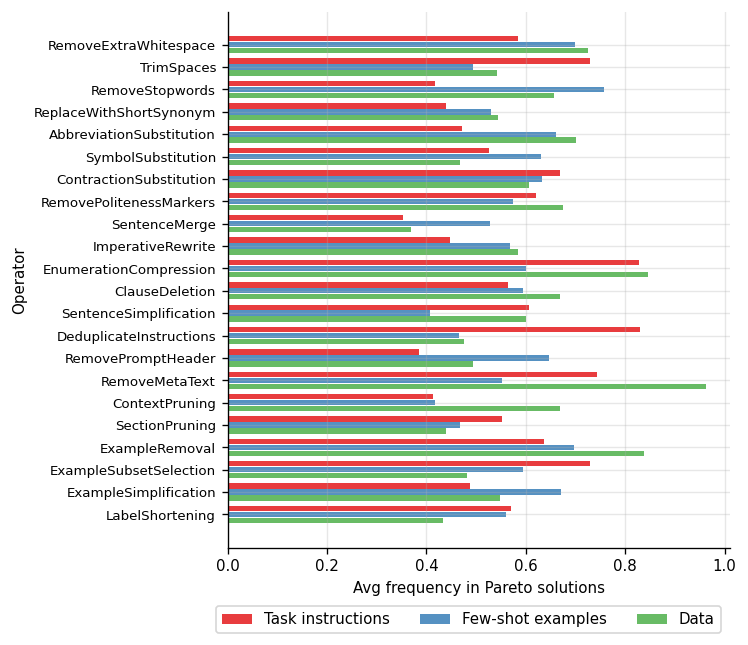

In [53]:
_SECTION_PREFIX = {'I': 'instruction', 'S': 'shots', 'D': 'data'}

# Canonical O1-O28 order (lexical -> syntactic -> structural -> semantic)
OP_ORDER = [
    'RemoveExtraWhitespace', 'TrimSpaces', 'RemoveStopwords', 'ReplaceWithShortSynonym',
    'AbbreviationSubstitution', 'SymbolSubstitution', 'ContractionSubstitution', 'RemovePolitenessMarkers',
    'SentenceMerge', 'ImperativeRewrite', 'EnumerationCompression', 'ClauseDeletion', 'SentenceSimplification',
    'DeduplicateInstructions', 'RemovePromptHeader', 'RemoveMetaText', 'ContextPruning', 'SectionPruning',
    'ExampleRemoval', 'ExampleSubsetSelection', 'ExampleSimplification', 'LabelShortening',
    'ContextCompression', 'InstructionSummarization', 'InstructionAbstraction', 'SchemaEncoding',
    'ExampleDistillation', 'ChunkCompression',
]


def collect_operator_usage():
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            sols = d['pareto_solutions']
            if not sols:
                continue

            op_section_counts = Counter()
            for sol in sols:
                for name in sol.get('transformation_names', []):
                    if ':' in name:
                        prefix, op_name = name.split(':', 1)
                        section = _SECTION_PREFIX.get(prefix, 'flat')
                    else:
                        op_name = name
                        section = 'flat'
                    op_section_counts[(op_name, section)] += 1

            for (op, section), cnt in op_section_counts.items():
                rows.append({
                    'model':     mlabel,
                    'task':      tlabel,
                    'operator':  op,
                    'section':   section,
                    'frequency': cnt / len(sols),
                })
    return pd.DataFrame(rows)


df_ops = collect_operator_usage()

if df_ops.empty:
    print('No operator usage data available.')
else:
    section_order    = ['instruction', 'shots', 'data', 'flat']
    sections_present = [s for s in section_order if s in df_ops['section'].unique()]

    section_colors = {s: c for s, c in zip(section_order, MODEL_COLORS)}

    # Average over models and tasks -> mean frequency per (operator, section)
    agg = df_ops.groupby(['operator', 'section'])['frequency'].mean().reset_index()

    # Operators in canonical O1-O28 order; append any unseen extras at the end
    ops_in_data = df_ops['operator'].unique().tolist()
    ops_ordered = [op for op in OP_ORDER if op in ops_in_data]
    ops_ordered += [op for op in ops_in_data if op not in OP_ORDER]

    pivot = (agg.pivot(index='operator', columns='section', values='frequency')
               .reindex(index=ops_ordered, columns=sections_present, fill_value=0))

    n_ops = len(ops_ordered)
    n_sec = len(sections_present)
    bar_h = 0.8 / n_sec

    fig, ax = plt.subplots(figsize=(COL1, ROW_H * 2))

    y_positions = np.arange(n_ops)

    section_labels = {
        'instruction': 'Task instructions',
        'shots':       'Few-shot examples',
        'data':        'Data',
        'flat':        'Flat',
    }

    for si, section in enumerate(sections_present):
        offset = (si - (n_sec - 1) / 2) * bar_h
        vals   = pivot[section].values
        ax.barh(y_positions + offset, vals, bar_h * 0.9,
                color=section_colors.get(section, '#888888'), alpha=0.85,
                label=section_labels.get(section, section))

    ax.set_yticks(y_positions)
    ax.set_yticklabels(ops_ordered, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('Avg frequency in Pareto solutions')
    ax.set_ylabel('Operator')

    handles, leg_labels = ax.get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc='lower center', bbox_to_anchor=(0.625, -0.075),
               ncol=len(handles), fontsize=9, frameon=True)
    plt.tight_layout()
    fig.subplots_adjust(bottom=0.08)
    fig.savefig(FIG_DIR / 'rq4_2_operators.pdf', bbox_inches='tight')
    plt.show()

---
## Paper Numbers — Reproduction Script

Reproduces every specific number cited in the Results section of the paper (§Results, RQ1–RQ4).
All values are computed directly from the JSON result files; no rounding is applied in the computation,
only in the final `print` statements to match the precision used in the text.

In [54]:
# ── Shared helpers ────────────────────────────────────────────────────────────

def get_baseline(d, name):
    return next((b for b in d['baselines'] if b['name'] == name), None)

def bl_tok(b):
    return b.get('test_avg_tokens') or b['search_avg_tokens']

def bl_perf(b):
    return b.get('test_avg_performance') or b['search_avg_performance']

def sol_tok(s):
    return s.get('test_avg_tokens') or s['search_avg_tokens']

def sol_perf(s):
    return s.get('test_avg_performance') or s['search_avg_performance']

# map stem → label for quick lookup
STEM_TO_LABEL = {stem: lbl for stem, lbl, _ in TASKS}
LABEL_TO_STEM = {lbl: stem for stem, lbl, _ in TASKS}
MODEL_DIR     = {lbl: mdir for lbl, mdir, _ in MODELS}

print("Helpers ready.")

Helpers ready.


### RQ1 — Compression–Performance Trade-off

In [55]:
print("=" * 70)
print("RQ1 — per-model / per-task Pareto front statistics")
print("=" * 70)

for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        pareto = d['pareto_solutions']
        nc     = get_baseline(d, 'no_compression')
        if not pareto or nc is None:
            continue

        orig_tok  = bl_tok(nc)
        orig_perf = bl_perf(nc)

        # Extreme points on the Pareto front
        min_tok_sol  = min(pareto, key=sol_tok)
        max_perf_sol = max(pareto, key=sol_perf)

        min_tok       = sol_tok(min_tok_sol)
        max_reduction = (1 - min_tok / orig_tok) * 100
        max_perf      = sol_perf(max_perf_sol)
        tok_at_max    = sol_tok(max_perf_sol)

        # Best solution that matches or exceeds uncompressed accuracy (parity)
        parity_sols   = [s for s in pareto if sol_perf(s) >= orig_perf]
        if parity_sols:
            best_parity     = min(parity_sols, key=sol_tok)
            parity_tok      = sol_tok(best_parity)
            parity_reduction = (1 - parity_tok / orig_tok) * 100
            parity_str = (f"parity at {parity_tok:.0f} tok "
                          f"({parity_reduction:.1f}% reduction)")
        else:
            parity_str = "NO parity solution on Pareto front"

        # Performance improvement over baseline at the best-performance point
        perf_delta = max_perf - orig_perf

        print(f"\n  {mlabel} / {tlabel}")
        print(f"    Uncompressed baseline : {orig_perf:.2f} @ {orig_tok:.0f} tok")
        print(f"    Max compression       : {min_tok:.0f} tok  ({max_reduction:.1f}% reduction)")
        print(f"    Best Pareto perf      : {max_perf:.2f} @ {tok_at_max:.0f} tok  "
              f"(Δ = {perf_delta:+.2f} vs. baseline)")
        print(f"    Parity                : {parity_str}")

RQ1 — per-model / per-task Pareto front statistics

  GPT-5.4-nano / MBPP
    Uncompressed baseline : 0.76 @ 719 tok
    Max compression       : 541 tok  (24.8% reduction)
    Best Pareto perf      : 0.72 @ 584 tok  (Δ = -0.04 vs. baseline)
    Parity                : NO parity solution on Pareto front

  GPT-5.4-nano / MMLU-Pro CS
    Uncompressed baseline : 0.70 @ 330 tok
    Max compression       : 83 tok  (74.9% reduction)
    Best Pareto perf      : 0.76 @ 322 tok  (Δ = +0.06 vs. baseline)
    Parity                : parity at 282 tok (14.5% reduction)

  GPT-5.4-nano / GSM8K
    Uncompressed baseline : 0.90 @ 807 tok
    Max compression       : 146 tok  (82.0% reduction)
    Best Pareto perf      : 0.96 @ 386 tok  (Δ = +0.06 vs. baseline)
    Parity                : parity at 197 tok (75.6% reduction)

  GPT-5.4-nano / BBH-Logic
    Uncompressed baseline : 0.92 @ 356 tok
    Max compression       : 186 tok  (47.6% reduction)
    Best Pareto perf      : 0.74 @ 337 tok  (Δ = -0.18 

### RQ2 — Comparison with Baselines

In [56]:
print("=" * 70)
print("RQ2 — average performance and token count per method")
print("    (aggregated across all models × common tasks, excluding MuSR)")
print("=" * 70)

# Collect per-(model, task) summary: best-Pareto-perf solution + each baseline
bl_perf_lists = defaultdict(list)
bl_tok_lists  = defaultdict(list)

COMMON_STEMS = [stem for stem, _, lo in TASKS if not lo]

for mlabel, mdir, _ in MODELS:
    for stem in COMMON_STEMS:
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        pareto = d['pareto_solutions']

        # NSGA-II: best-performance solution on the Pareto front
        if pareto:
            best = max(pareto, key=sol_perf)
            bl_perf_lists['NSGA-II (compromise)'].append(sol_perf(best))
            bl_tok_lists['NSGA-II (compromise)'].append(sol_tok(best))

        # Each named baseline
        for b in d['baselines']:
            bname = b['name']
            bl_perf_lists[bname].append(bl_perf(b))
            bl_tok_lists[bname].append(bl_tok(b))

# Display order
DISPLAY_ORDER = [
    ('NSGA-II (compromise)',    'NSGA-II (best-perf Pareto solution)'),
    ('no_compression',   'No compression'),
    ('random_search',    'Random search'),
    ('multi_armed_bandit', 'Multi-Armed Bandit'),
    ('random_deletion',  'Random deletion'),
    ('llmlingua2',       'LLMLingua-2'),
    ('truncated_prompt', 'Truncated prompt'),
    ('summarization',    'Summarization'),
    ('all_transformations', 'All transformations'),
]

print(f"\n  {'Method':<35} {'Avg perf':>9}  {'Avg tokens':>10}  {'N':>4}")
print(f"  {'-'*35} {'-'*9}  {'-'*10}  {'-'*4}")
for key, label in DISPLAY_ORDER:
    perfs = bl_perf_lists.get(key, [])
    toks  = bl_tok_lists.get(key, [])
    if not perfs:
        continue
    avg_p = np.mean(perfs)
    avg_t = np.mean(toks)
    print(f"  {label:<35} {avg_p:>9.3f}  {avg_t:>10.0f}  {len(perfs):>4}")

# Average token reduction at parity for NSGA-II vs no-compression
nc_avg_tok   = np.mean(bl_tok_lists['no_compression'])
nsga_avg_tok = np.mean(bl_tok_lists['NSGA-II (compromise)'])
tok_reduction = (1 - nsga_avg_tok / nc_avg_tok) * 100
print(f"\n  Token reduction (NSGA-II best vs. no compression): {tok_reduction:.0f}%")
print(f"  ({nc_avg_tok:.0f} → {nsga_avg_tok:.0f} avg tokens)")

RQ2 — average performance and token count per method
    (aggregated across all models × common tasks, excluding MuSR)

  Method                               Avg perf  Avg tokens     N
  ----------------------------------- ---------  ----------  ----
  NSGA-II (best-perf Pareto solution)     0.694         381    16
  No compression                          0.671         581    16
  Random search                           0.409         352    16
  Multi-Armed Bandit                      0.483         384    16
  Random deletion                         0.380         390    16
  LLMLingua-2                             0.036         321    16
  Truncated prompt                        0.022         260    16
  Summarization                           0.019          50    16
  All transformations                     0.005          54    16

  Token reduction (NSGA-II best vs. no compression): 34%
  (581 → 381 avg tokens)


### RQ3 — Cost and Convergence

In [57]:
print("=" * 70)
print("RQ3.1 — Timing: total minutes per (model, task, approach)")
print("=" * 70)

timing_rows = []
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        nsga2_min = (d['search_elapsed_seconds'] + d['eval_elapsed_seconds']) / 60
        timing_rows.append({'model': mlabel, 'task': tlabel,
                            'approach': 'NSGA-II', 'minutes': nsga2_min})
        for b in d['baselines']:
            bname = b['name']
            label = BASELINE_STYLE.get(bname, {}).get('label', bname)
            secs  = b.get('elapsed_seconds', np.nan)
            timing_rows.append({'model': mlabel, 'task': tlabel,
                                'approach': label, 'minutes': secs / 60})

df_timing = pd.DataFrame(timing_rows)

# Per-(model, task) detail for NSGA-II
print("\n  NSGA-II wall-clock time:")
nsga_times = df_timing[df_timing['approach'] == 'NSGA-II'].dropna(subset=['minutes'])
for _, row in nsga_times.sort_values('minutes').iterrows():
    h = row['minutes'] / 60
    print(f"    {row['model']:<18} / {row['task']:<14} : {row['minutes']:>7.1f} min  ({h:.1f} h)")

print(f"\n  Range: {nsga_times['minutes'].min():.0f} – {nsga_times['minutes'].max():.0f} min  "
      f"({nsga_times['minutes'].min()/60:.1f} – {nsga_times['minutes'].max()/60:.1f} h)")

# Ratio: NSGA-II vs Random Search and MAB per (model, task)
print("\n  NSGA-II / Random-Search and NSGA-II / MAB ratios:")
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        nsga2_min = (d['search_elapsed_seconds'] + d['eval_elapsed_seconds']) / 60
        rs  = get_baseline(d, 'random_search')
        mab = get_baseline(d, 'multi_armed_bandit')
        rs_min  = rs.get('elapsed_seconds', np.nan) / 60  if rs  else np.nan
        mab_min = mab.get('elapsed_seconds', np.nan) / 60 if mab else np.nan
        rs_ratio  = nsga2_min / rs_min  if not np.isnan(rs_min)  and rs_min  > 0 else np.nan
        mab_ratio = nsga2_min / mab_min if not np.isnan(mab_min) and mab_min > 0 else np.nan
        print(f"    {mlabel:<18} / {tlabel:<14}: "
              f"NSGA2/RS={rs_ratio:.1f}×   NSGA2/MAB={mab_ratio:.1f}×")

RQ3.1 — Timing: total minutes per (model, task, approach)

  NSGA-II wall-clock time:
    GPT-5.4-nano       / MBPP           :   147.8 min  (2.5 h)
    GPT-5.4-nano       / GSM8K          :   186.8 min  (3.1 h)
    GPT-5.4-nano       / MMLU-Pro CS    :   235.7 min  (3.9 h)
    Qwen3.5-9B         / MBPP           :   391.0 min  (6.5 h)
    GPT-5.4-nano       / BBH-Logic      :   546.0 min  (9.1 h)
    Gemini-3-Flash     / MBPP           :   608.8 min  (10.1 h)
    Gemma-4-26B        / MBPP           :   775.7 min  (12.9 h)
    Qwen3.5-9B         / GSM8K          :  1236.4 min  (20.6 h)
    Gemini-3-Flash     / BBH-Logic      :  1662.5 min  (27.7 h)
    Gemini-3-Flash     / MMLU-Pro CS    :  1821.9 min  (30.4 h)
    Gemma-4-26B        / GSM8K          :  1950.1 min  (32.5 h)
    Qwen3.5-9B         / BBH-Logic      :  1954.2 min  (32.6 h)
    Qwen3.5-9B         / MMLU-Pro CS    :  2062.9 min  (34.4 h)
    Gemini-3-Flash     / GSM8K          :  2332.5 min  (38.9 h)
    Gemma-4-26B        

In [58]:
print("=" * 70)
print("RQ3.2 — Convergence: generation at which best-perf and min-token plateau")
print("=" * 70)

PLATEAU_THRESHOLD = 0.01   # change < 1% of range considered converged

for tlabel, entries in conv_data.items():
    print(f"\n  Task: {tlabel}")
    perf_plateaus = []
    tok_plateaus  = []

    for entry in entries:
        gen_map  = {h['generation']: h for h in entry['history']}
        ref_tok  = max(entry['ref_tokens'], 1)
        gens_all = sorted(gen_map.keys())

        best_perfs = []
        min_toks   = []
        for g in gens_all:
            h = gen_map[g]
            if h['pareto_front']:
                best_perfs.append(max(s['avg_performance'] for s in h['pareto_front']))
                min_toks.append(min(s['avg_tokens']       for s in h['pareto_front']) / ref_tok)
            else:
                best_perfs.append(np.nan)
                min_toks.append(np.nan)

        best_perfs = np.array(best_perfs)
        min_toks   = np.array(min_toks)

        # Find first generation where value stays within threshold of final value
        def plateau_gen(series, gens):
            final = series[~np.isnan(series)][-1]
            rng   = np.nanmax(series) - np.nanmin(series)
            thr   = PLATEAU_THRESHOLD * rng if rng > 0 else 0
            for i, (g, v) in enumerate(zip(gens, series)):
                if np.isnan(v):
                    continue
                if all(abs(series[j] - final) <= thr
                       for j in range(i, len(series)) if not np.isnan(series[j])):
                    return g
            return gens[-1]

        perf_plateaus.append(plateau_gen(best_perfs, gens_all))
        tok_plateaus.append(plateau_gen(min_toks,    gens_all))

    print(f"    Best-perf plateau generation  : "
          f"mean={np.mean(perf_plateaus):.1f}  range {min(perf_plateaus)}–{max(perf_plateaus)}")
    print(f"    Min-token plateau generation  : "
          f"mean={np.mean(tok_plateaus):.1f}  range {min(tok_plateaus)}–{max(tok_plateaus)}")

print(f"\n  (Plateau = first generation from which the value stays within "
      f"{PLATEAU_THRESHOLD*100:.0f}% of the final value)")

RQ3.2 — Convergence: generation at which best-perf and min-token plateau

  Task: MBPP
    Best-perf plateau generation  : mean=1.8  range 1–4
    Min-token plateau generation  : mean=10.8  range 7–13

  Task: MMLU-Pro CS
    Best-perf plateau generation  : mean=5.2  range 2–13
    Min-token plateau generation  : mean=8.0  range 6–13

  Task: GSM8K
    Best-perf plateau generation  : mean=4.8  range 1–10
    Min-token plateau generation  : mean=8.5  range 3–14

  Task: BBH-Logic
    Best-perf plateau generation  : mean=4.8  range 1–9
    Min-token plateau generation  : mean=7.0  range 5–8

  (Plateau = first generation from which the value stays within 1% of the final value)


### RQ4 — Operator Patterns and Transferability

In [59]:
print("=" * 70)
print("RQ4.1 — Transfer experiment: native vs. transferred Pareto solutions")
print("=" * 70)

for mlabel, mdir, _ in MODELS:
    printed_header = False
    for src_stem, tgt_stem in TRANSFER_PAIRS:
        key = f'transfer_{src_stem}_to_{tgt_stem}'
        tr  = RESULTS[mdir].get(key)
        nat = RESULTS[mdir].get(tgt_stem)
        if tr is None or nat is None:
            continue

        if not printed_header:
            print(f"\n  Model: {mlabel}")
            printed_header = True

        src_lbl = STEM_TO_LABEL.get(src_stem, src_stem)
        tgt_lbl = STEM_TO_LABEL.get(tgt_stem, tgt_stem)

        nat_perfs = [sol_perf(s) for s in nat['pareto_solutions']]
        nat_toks  = [sol_tok(s)  for s in nat['pareto_solutions']]
        tr_perfs  = [sol_perf(s) for s in tr['solutions']]
        tr_toks   = [sol_tok(s)  for s in tr['solutions']]

        nat_avg_p = np.mean(nat_perfs)
        nat_avg_t = np.mean(nat_toks)
        tr_avg_p  = np.mean(tr_perfs)
        tr_avg_t  = np.mean(tr_toks)

        # Performance retention = transferred_perf / native_perf
        perf_retention = tr_avg_p / nat_avg_p * 100 if nat_avg_p > 0 else np.nan
        tok_ratio      = tr_avg_t / nat_avg_t

        print(f"    {src_lbl} → {tgt_lbl}")
        print(f"      Native NSGA-II : perf={nat_avg_p:.3f}  tok={nat_avg_t:.0f}")
        print(f"      Transferred    : perf={tr_avg_p:.3f}  tok={tr_avg_t:.0f}")
        print(f"      Retention      : perf={perf_retention:.0f}%   "
              f"tok ratio={tok_ratio:.2f}×  "
              f"({'MORE' if tok_ratio > 1 else 'FEWER'} tokens than native)")

RQ4.1 — Transfer experiment: native vs. transferred Pareto solutions

  Model: GPT-5.4-nano
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.478  tok=275
      Transferred    : perf=0.482  tok=319
      Retention      : perf=101%   tok ratio=1.16×  (MORE tokens than native)
    BBH-Logic → GSM8K
      Native NSGA-II : perf=0.690  tok=253
      Transferred    : perf=0.629  tok=536
      Retention      : perf=91%   tok ratio=2.11×  (MORE tokens than native)

  Model: Gemini-3-Flash
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.036  tok=206
      Transferred    : perf=0.098  tok=295
      Retention      : perf=272%   tok ratio=1.43×  (MORE tokens than native)
    BBH-Logic → GSM8K
      Native NSGA-II : perf=0.372  tok=354
      Transferred    : perf=0.139  tok=454
      Retention      : perf=37%   tok ratio=1.28×  (MORE tokens than native)

  Model: Gemma-4-26B
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.322  tok=271
      Transferred    : perf=0.551  tok=329
      Reten

In [60]:
print("=" * 70)
print("RQ4.2 — Operator usage: mean frequency in Pareto solutions per section")
print("=" * 70)

_SECTION_PREFIX = {'I': 'instruction', 'S': 'shots', 'D': 'data'}

# Build DataFrame of (model, task, operator, section, frequency) — same as df_ops above
op_rows = []
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        sols = d['pareto_solutions']
        if not sols:
            continue
        op_section_counts = Counter()
        for sol in sols:
            for name in sol.get('transformation_names', []):
                if ':' in name:
                    prefix, op_name = name.split(':', 1)
                    section = _SECTION_PREFIX.get(prefix, 'flat')
                else:
                    op_name, section = name, 'flat'
                op_section_counts[(op_name, section)] += 1
        for (op, section), cnt in op_section_counts.items():
            op_rows.append({'model': mlabel, 'task': tlabel,
                            'operator': op, 'section': section,
                            'frequency': cnt / len(sols)})

df_op = pd.DataFrame(op_rows)

for section in ['instruction', 'shots', 'data']:
    sub = df_op[df_op['section'] == section]
    if sub.empty:
        continue
    overall_mean = sub.groupby('operator')['frequency'].mean().sort_values(ascending=False)
    top10 = overall_mean.head(10)
    bottom3 = overall_mean.tail(3)

    print(f"\n  Section: {section}")
    print(f"    Overall mean freq. range: {overall_mean.min():.3f} – {overall_mean.max():.3f}")
    print(f"    Top operators (overall mean freq.):")
    for op, freq in top10.items():
        # per-task breakdown
        per_task = sub[sub['operator'] == op].groupby('task')['frequency'].mean()
        task_str = "  ".join(f"{t}={v:.2f}" for t, v in per_task.items())
        print(f"      {op:<30}  mean={freq:.3f}   [{task_str}]")
    print(f"    Bottom operators:")
    for op, freq in bottom3.items():
        print(f"      {op:<30}  mean={freq:.3f}")

RQ4.2 — Operator usage: mean frequency in Pareto solutions per section

  Section: instruction
    Overall mean freq. range: 0.352 – 0.830
    Top operators (overall mean freq.):
      DeduplicateInstructions         mean=0.830   [BBH-Logic=0.85  GSM8K=0.96  MBPP=0.59  MMLU-Pro CS=0.93]
      EnumerationCompression          mean=0.828   [BBH-Logic=0.90  GSM8K=0.73  MBPP=0.76  MMLU-Pro CS=0.90]
      RemoveMetaText                  mean=0.743   [BBH-Logic=0.75  GSM8K=0.65  MBPP=0.76  MMLU-Pro CS=0.83]
      TrimSpaces                      mean=0.730   [BBH-Logic=0.67  GSM8K=0.81  MBPP=0.93  MMLU-Pro CS=0.50]
      ExampleSubsetSelection          mean=0.729   [BBH-Logic=0.78  GSM8K=0.60  MBPP=0.77  MMLU-Pro CS=0.78]
      ContractionSubstitution         mean=0.670   [BBH-Logic=0.57  GSM8K=0.93  MBPP=0.36  MMLU-Pro CS=0.66]
      ExampleRemoval                  mean=0.636   [BBH-Logic=0.47  GSM8K=0.95  MBPP=0.72  MMLU-Pro CS=0.53]
      RemovePolitenessMarkers         mean=0.620   [BBH-Lo